In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

In [2]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [15]:
PATH_data = f"../../../../mnt/d/swamp_data/genotype/"

In [16]:
os.listdir(PATH_data)

['full', 'raw', 'segmented', 'raw_LDs']

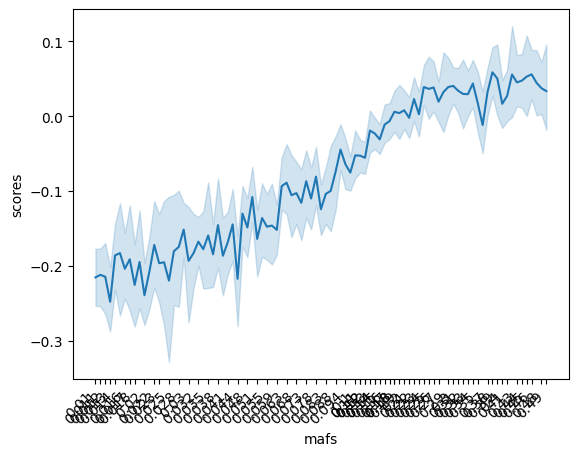

In [30]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir(PATH_data)]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"{PATH_data}/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['super_pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::100], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

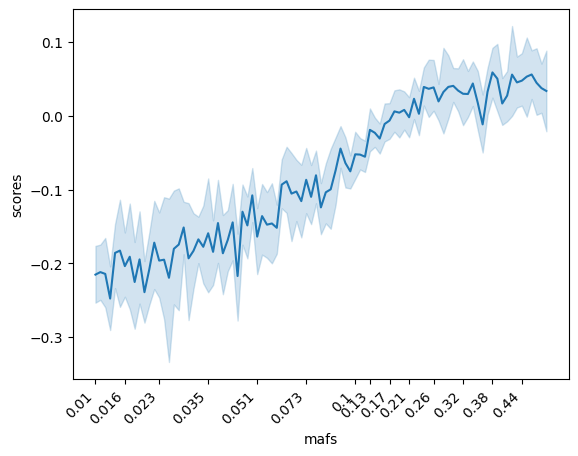

In [33]:
df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::100], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

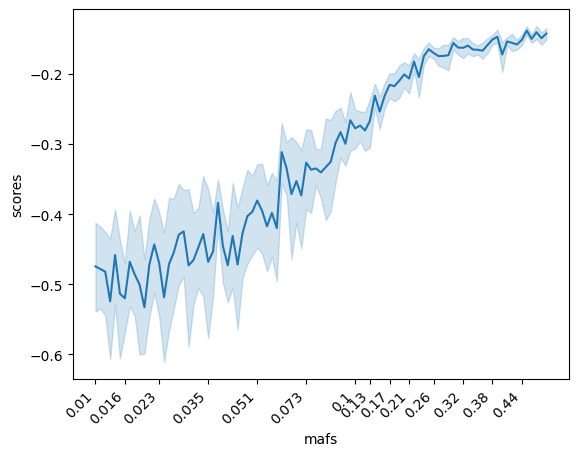

In [34]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir(PATH_data)]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"{PATH_data}/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::100], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

In [17]:
import numpy as np

# Generate sample data
x = np.random.normal(0, 1, 100)
y = np.random.normal(0, 1, 100)

# Calculate the median for each axis
x_median = np.median(x)
y_median = np.median(y)

# Calculate the IQR for each axis
x_q1, x_q3 = np.percentile(x, [25, 75])
x_iqr = x_q3 - x_q1

y_q1, y_q3 = np.percentile(y, [25, 75])
y_iqr = y_q3 - y_q1

# Calculate the upper and lower bounds for each axis
x_upper_bound = x_q3 + 1.5 * x_iqr
x_lower_bound = x_q1 - 1.5 * x_iqr

y_upper_bound = y_q3 + 1.5 * y_iqr
y_lower_bound = y_q1 - 1.5 * y_iqr

# Find the outliers for each axis
x_outliers = x[(x < x_lower_bound) | (x > x_upper_bound)]
y_outliers = y[(y < y_lower_bound) | (y > y_upper_bound)]

# Print the outliers
print("Outliers for x:", x_outliers)
print("Outliers for y:", y_outliers)

Outliers for x: [ 2.46855504 -2.39343271]
Outliers for y: [-2.26755568 -2.5260584  -2.20444166  1.98432069]
